Load step (1)/30
  Newton converged in 1 iterations
Load step (2)/30
  Newton converged in 2 iterations
Load step (3)/30
  Newton converged in 2 iterations
Load step (4)/30
  Newton converged in 2 iterations
Load step (5)/30
  Newton converged in 2 iterations
Load step (6)/30
  Newton converged in 2 iterations
Load step (7)/30
  Newton converged in 2 iterations
Load step (8)/30
  Newton converged in 2 iterations
Load step (9)/30
  Newton converged in 2 iterations
Load step (10)/30
  Newton converged in 2 iterations
Load step (11)/30
  Newton converged in 2 iterations
Load step (12)/30
  Newton converged in 2 iterations
Load step (13)/30
  Newton converged in 2 iterations
Load step (14)/30
  Newton converged in 2 iterations
Load step (15)/30
  Newton converged in 2 iterations
Load step (16)/30
  Newton converged in 2 iterations
Load step (17)/30
  Newton converged in 2 iterations
Load step (18)/30
  Newton converged in 2 iterations
Load step (19)/30
  Newton converged in 2 iterations
Lo

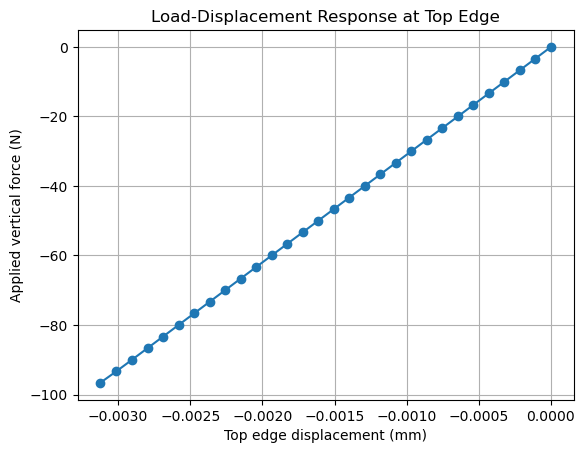

In [ ]:
import gmsh
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time 
#CREATION OF A 2D BEAM MESH USING GMSH
gmsh.initialize()
gmsh.model.add("beam_only")

# Mesh size
lc = 0.5 #[mm]

# Beam geometry (you can change these)
beam_width  = 5     # width in x [mm]
beam_height = 5    # height in y [mm]

xL = beam_width- beam_width/2   # left x
xR = beam_width + beam_width/2   # right x
yB = 0.0                  # bottom
yT = beam_height          # top

# Points (counter-clockwise)
p1 = gmsh.model.geo.addPoint(xL, yB, 0, lc, 1)
p2 = gmsh.model.geo.addPoint(xR, yB, 0, lc, 2)
p3 = gmsh.model.geo.addPoint(xR, yT, 0, lc, 3)
p4 = gmsh.model.geo.addPoint(xL, yT, 0, lc, 4)

# Lines
l1 = gmsh.model.geo.addLine(1, 2)
l2 = gmsh.model.geo.addLine(2, 3)
l3 = gmsh.model.geo.addLine(3, 4)
l4 = gmsh.model.geo.addLine(4, 1)

# Surface
loop_beam = gmsh.model.geo.addCurveLoop([l1, l2, l3, l4])
surf_beam = gmsh.model.geo.addPlaneSurface([loop_beam], 1)

gmsh.model.geo.synchronize()

# Physical group for the beam
gmsh.model.addPhysicalGroup(2, [surf_beam], 1)
gmsh.model.setPhysicalName(2, 1, "Beam")

# Mesh
gmsh.option.setNumber("Mesh.ElementOrder", 1)
gmsh.option.setNumber("Mesh.Algorithm", 6)
gmsh.model.mesh.generate(2)

gmsh.write("beam_only.msh")
gmsh.finalize()


# VISUALIZATION OF THE MESH USING MATPLOTLIB
gmsh.initialize()
gmsh.open("beam_only.msh")   # <-- new mesh file

# Nodes
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
node_coords = np.array(node_coords).reshape(-1, 3)

def get_elements_of_physical_group(dim, tag):
    entity_tags = gmsh.model.getEntitiesForPhysicalGroup(dim, tag)
    all_elements = []
    for entity_tag in entity_tags:
        elem_types, elem_tags, elem_node_tags = gmsh.model.mesh.getElements(dim, entity_tag)
        for i in range(len(elem_types)):
            all_elements.append(np.array(elem_node_tags[i]).reshape(-1, 3))
    return np.concatenate(all_elements) if all_elements else np.array([])

elements_beam = get_elements_of_physical_group(2, 1)
'''
plt.figure(figsize=(6, 8))
if elements_beam.size > 0:
    plt.triplot(
        node_coords[:, 0],
        node_coords[:, 1],
        elements_beam - 1,
        color='blue',
        label='Beam'
    )

plt.gca().set_aspect('equal')
plt.title('Beam mesh')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

gmsh.finalize()
'''


#FUNCTIONS USED ON THE ELASTIC PROBLEM SOLUTION 
# First, lets remove all the third coordinates of the nodes (all are zero!) because we are in 2D if we were in 3D would be different

coord = node_coords[:,:2]



def jacobian(coord):
 
  return np.abs((coord[0,0]-coord[0,2]) * (coord[1,1]-coord[1,2]) - (coord[0,1] - coord[0,2]) * (coord[1,0] - coord[1,2]))

def B_matrix(coord):

    x1, x2, x3 = coord[0]
    y1, y2, y3 = coord[1]
    Α2 = x1*(y2 - y3) + x2*(y3 - y1) + x3*(y1 - y2)
    # Derivatives of shape functions
    dNdx = np.array([(y2 - y3) / Α2,(y3 - y1) / Α2,(y1 - y2) / Α2 ])

    dNdy = np.array([  (x3 - x2) / Α2, (x1 - x3) / Α2, (x2 - x1) / Α2])
    B = np.zeros((3, 6))
    B[0, 0::2] = dNdx          # ε_xx
    B[1, 1::2] = dNdy          # ε_yy
    B[2, 0::2] = dNdy          # γ_xy (u_x part)
    B[2, 1::2] = dNdx          # γ_xy (u_y part)

    return B


def D_matrix(E, nu, plane_stress=False):  #σ=Dε
    if plane_stress:
        coef = E / (1.0 - nu**2)
        D = coef * np.array([
            [1.0,   nu,           0.0],
            [nu,    1.0,          0.0],
            [0.0,   0.0, (1.0 - nu)/2.0]
        ])
    else:
        coef = E / ((1.0 + nu)*(1.0 - 2.0*nu))
        D = coef * np.array([
            [1.0 - nu,    nu,           0.0],
            [nu,          1.0 - nu,     0.0],
            [0.0,         0.0, 0.5*(1.0 - 2.0*nu)]
        ])
    return D


def CST_elastic(coord, E, nu, t=1.0, plane_stress=False):

    A = jacobian(coord) / 2.0
    B = B_matrix(coord)  
    D = D_matrix(E, nu, plane_stress)

    Ke = t * A * (B.T @ D @ B)
    return Ke

def assemble_global_stiffness(node_coords, elements, E, nu, t=1.0, plane_stress=False):


    n_nodes = node_coords.shape[0]
    n_dof   = 2 * n_nodes  # ux, uy per node
    elements=elements-1
    K = np.zeros((n_dof, n_dof))

    for elem in elements:
        # elem is [n1, n2, n3] node indices
        n1, n2, n3 = elem

        # Build coord for this element: 2x3
        coord = np.array([
            [node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]],
            [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]],
        ])

        # Element stiffness
        Ke = CST_elastic(coord, E, nu, t=t, plane_stress=plane_stress)  # 6x6

        # DOF mapping: [ux1, uy1, ux2, uy2, ux3, uy3]
        edof = np.array([
            2*n1, 2*n1 + 1,
            2*n2, 2*n2 + 1,
            2*n3, 2*n3 + 1])

        # Assemble Ke into global K
        for i_local in range(6):
            I = edof[i_local]
            for j_local in range(6):
                J = edof[j_local]
                K[I, J] += Ke[i_local, j_local]

    return K

def applied_force_upper_surface(node_coords, Load, direction):
  Force=np.zeros(len(node_coords)*2)
  force_indices=np.where(node_coords[:,1]==yT)[0] #the indices of the nodes on the top edge
  force_indices_corners=np.array([np.where((node_coords[:,0]==xL) & (node_coords[:,1]==yT))[0][0],  np.where((node_coords[:,0]==xR) & (node_coords[:,1]==yT))[0][0]])
  force_indices=np.setdiff1d(force_indices, force_indices_corners) #removing
  
  if direction=='x':
    Force[2*force_indices]=Load/(len(force_indices)-1)
    Force[2*force_indices_corners]=Load/((len(force_indices)-1))/2 #applying half load on the corner nodes
  elif direction=='y':
    Force[2*force_indices+1]=-Load/(len(force_indices)-1)
    Force[2*force_indices_corners+1]=-Load/((len(force_indices)-1))/2 #applying half load on the corner nodes
  return Force

def applied_boundary_conditions_bottom_surface(node_coords,  direction):
  ##### ON THE BOTTOM EDGE DISPLACEMENT IN Y-AXIS IS CONTRSAINED
  bottom_indices=np.where(node_coords[:,1]==0)[0]

# Combine indices for degrees of freedom to remove
  dof_to_remove = []

# Add bottom edge DOFs (Y-axis displacement constrained)
  for idx in bottom_indices:
    if direction=='x':
      dof_to_remove.append(2 * idx)  # u_x DOF
    elif direction=='y':
      dof_to_remove.append(2 * idx + 1)  # u_y DOF
    elif direction=='xy':
      dof_to_remove.append(2 * idx)  # u_x DOF
      dof_to_remove.append(2 * idx + 1)  # u_y DOF
  return dof_to_remove


# Apply boundary conditions on the global matrices
def apply_boundary_conditions(K_mechanical,Force, dof_to_remove):
    # Convert to NumPy arrays for indexing
    dof_to_keep = np.array([i for i in range(K_mechanical.shape[0]) if i not in dof_to_remove])

    # Reduce stiffness matrix and force vector
    K_mechanical_reduced = K_mechanical[dof_to_keep,:][:, dof_to_keep]
    Force_reduced=Force[dof_to_keep]

    return K_mechanical_reduced, Force_reduced, dof_to_keep

#### Solve of the equation K_mechanical*u=F
def solve_mechanical_response(K_mechanical_input, F_input):
    # Solve for displacements
    dof_to_remove=applied_boundary_conditions_bottom_surface(node_coords,'xy')
    # Use the input K_mechanical_input and F_input for boundary condition application
    K_mechanical_reduced,Force_reduced, dof_to_keep = apply_boundary_conditions(K_mechanical_input, F_input, dof_to_remove)
    # Solve using the reduced stiffness matrix and the reduced force vector
    u = np.linalg.solve(K_mechanical_reduced, Force_reduced)

    #### Go to initial shape of the displacement vector

    U_global=np.zeros(2*len(node_coords))
    U_global[dof_to_keep]=u

    return U_global # Return U_global, not u



#####TRY TO COMPUTE THE STRESSES#####################

def compute_stress_plane_strain(coord, elements, D, u_global_vector):
    stresses = []  # To store stresses for each element
    elements_0_indexed = elements - 1  # Convert to zero-based indexing

    for elem_nodes in elements_0_indexed:
        # Get the node indices for the current element
        n1, n2, n3 = elem_nodes
        coords_element = coord[elem_nodes].T 
        B = B_matrix(coords_element)

        edof = np.array([
            2*n1, 2*n1 + 1,
            2*n2, 2*n2 + 1,
            2*n3, 2*n3 + 1])
        u_local = u_global_vector[edof] 

        strain = np.dot(B, u_local)

        stress = np.dot(D, strain)
        stresses.append(stress)

    return stresses


#stress=compute_stress_plane_strain(coord,elements_beam,D_matrix(E,nu,plane_stress=False),U_global)

#s=np.array(stress)

################_____CREATING VON MISES STRESS VEtROR TO BE ABLE TO VISUALISE THE STRESSES###############
def von_mises_stress_plane_strain(sigma_x, sigma_y, tau_xy, nu):

    sigma_z = nu * (sigma_x + sigma_y)
    von_mises = np.sqrt(
        sigma_x**2 + sigma_y**2 + sigma_z**2
        - sigma_x * sigma_y - sigma_y * sigma_z - sigma_z * sigma_x
        + 3 * tau_xy**2
    )
    return von_mises


################_____CREATING VON MISES STRESS VECROR TO BE ABLE TO VISUALISE THE STRESSES###############
def von_mises_stresses(stress,nu):
    von_mises_global=np.zeros(len(stress))
    for i in range(len(stress)):
        sigma_x=stress[i][0]
        sigma_y=stress[i][1]
        tau_xy=stress[i][2]
        sigma_z = nu * (sigma_x + sigma_y)
        von_mises=von_mises_stress_plane_strain(sigma_x,sigma_y,tau_xy, nu)
        von_mises_global[i]=von_mises
    return von_mises_global

#von_mises=von_mises_stresses(s,nu)
### Create a yield function computation
def yield_function(stress,E,nu,sigma_y0,kappa):
    sigma_x = stress[0]
    sigma_y = stress[1]
    tau_xy  = stress[2]
    sigma_zz = nu * (sigma_x + sigma_y)  # plane strain

    sigma_tensor = np.array([
        [sigma_x, tau_xy, 0.0],
        [tau_xy, sigma_y, 0.0],
        [0.0,    0.0,    sigma_zz] ])

    # hydrostatic pressure and deviatoric part
    p = np.trace(sigma_tensor) / 3.0
    I = np.identity(3)
    S_tr = sigma_tensor - p * I

    # von Mises eq. stress
    S_dot_S = np.tensordot(S_tr, S_tr, axes=2)
    sigma_eq_tr = np.sqrt(1.5 * S_dot_S)

    # current yield stress with softening
    sigma_y_curr = sigma_y0 - H * kappa

    # trial yield function
    f_tr = sigma_eq_tr - sigma_y_curr
    return f_tr

# Consistent elastoplastic tangent for isotropic von Mises plasticity
def compute_Cep(C, sigma_trial, sigma_y, alpha, H):
    s = sigma_trial - np.mean(sigma_trial[:2])*np.array([1,1,0])
    norm_s = np.linalg.norm(s) * np.sqrt(1.5)
    f_trial = norm_s - (sigma_y + H*alpha)
    if f_trial <= 0:
        #return C, _  # elastic
        return C # elastic
    else:
        #print('Ayayaya')
        n = s / np.linalg.norm(s)
        #print(n)
        n = n.reshape(3,1)
        Ce = C - (C @ n @ n.T @ C) / (n.T @ C @ n + H)
        #return Ce, n
        return Ce
    
     

#FUNCTIONS FOR PLASTICITY CALCULATIONS
def calculate_von_mises_stress(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_z = nu * (sigma_x + sigma_y) # Plane strain
    return np.sqrt(
        sigma_x**2 + sigma_y**2 + sigma_z**2
        - sigma_x * sigma_y - sigma_y * sigma_z - sigma_z * sigma_x
        + 3 * tau_xy**2 )

# Definition of deviatoric stress components for a stress vector [sigma_x, sigma_y, tau_xy]
def deviatoric_part(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_zz = nu * (sigma_x + sigma_y) # Plane strain
    p = (sigma_x + sigma_y + sigma_zz) / 3.0
    Sx = sigma_x - p
    Sy = sigma_y - p
    # Sz = sigma_zz - p # Not explicitly needed for 2D Voigt vector output
    return np.array([Sx, Sy, tau_xy])

# Definition of hydrostatic pressure for a stress vector [sigma_x, sigma_y, tau_xy]
def hydrostatic_part(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_zz = nu * (sigma_x + sigma_y) # Plane strain
    return (sigma_x + sigma_y + sigma_zz) / 3.0


# Yield function (adapted from cH4cZuiTJO1A, now takes required parameters as arguments)
def yield_function_plasticity(stress_vector, E_val, nu_val, sigma_y0_val, kappa_val, H_val):
    sigma_x = stress_vector[0]
    sigma_y = stress_vector[1]
    tau_xy  = stress_vector[2]
    sigma_zz = nu_val * (sigma_x + sigma_y)  # plane strain

    sigma_tensor = np.array([
        [sigma_x, tau_xy, 0.0],
        [tau_xy, sigma_y, 0.0],
        [0.0,    0.0,    sigma_zz] ])

    p = np.trace(sigma_tensor) / 3.0
    I_3d = np.identity(3)
    S_tr_matrix = sigma_tensor - p * I_3d

    S_dot_S = np.tensordot(S_tr_matrix, S_tr_matrix, axes=2)
    sigma_eq_tr = np.sqrt(1.5 * S_dot_S)

    sigma_y_curr = sigma_y0_val + H_val * kappa_val
    f_tr = sigma_eq_tr - sigma_y_curr
    return f_tr

###add the elastic prediction corrector
num_nodes = len(node_coords)
n_elem = len(elements_beam)

# Material parameters (E and nu are assumed to be in global scope from eg_ruPiNgze7)
E  = 30*1e3 #MPa  -> concrete
nu = 0.2
t  = 1.0 #[mm]
G  = E / (2.0 * (1.0 + nu))
sigma_y0 = 30.0
Et = E / 100.0
H  = -E * Et / (E - Et)

# Internal variables per integration point / element
kappa = np.zeros(n_elem)           # history variable κ (equiv. plastic strain)
sigma_eq = np.zeros(n_elem)        # equivalent stress for post-processing
yield_func_history = np.zeros(n_elem) # φ = σ_eq - σ_y for post-processing
current_stress_per_element = np.zeros((n_elem, 3))  #initial elastic solution

num_steps = 30
F_total = applied_force_upper_surface(node_coords, 100.0, 'y') # F_total in kernel
U = np.zeros(2 * len(node_coords))
max_iter = 30



# --- CONTROL BOUNDARY: top edge nodes (where you apply the load) ---
y_coords = node_coords[:, 1]
y_max = np.max(y_coords)
tol = 1e-6  # small tolerance in case of round-off

top_nodes = np.where(np.abs(y_coords - y_max) < tol)[0]  # indices of nodes on top edge
top_dofs_y = 2 * top_nodes + 1   # y-DOFs of those nodes   (ux = 2*i, uy = 2*i+1)

# Histories for global response
u_top_history = []   # control displacement (average vertical disp on top)
F_top_history = []   # total applied vertical force on top












for step in range(0, num_steps):
    print(f'Load step ({step+1})/{num_steps}')

    F_step = F_total * step / num_steps
    F = F_step.copy()


    iter = 0
    while iter < max_iter:
        K = np.zeros((2 * num_nodes, 2 * num_nodes))
        R = F.copy()   # external forces

        for e in range(n_elem):
            n1, n2, n3 = (elements_beam[e] - 1).astype(int)   # or map(int, elements_beam[e]-1)

            element_coord = np.array([
                [node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]],
                [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]],
            ])
            B_e = B_matrix(element_coord)
            A   = jacobian(element_coord) / 2.0

            # --- 1. element dofs and strain from CURRENT U ---
            edof = np.array([2*n1, 2*n1 + 1,2*n2, 2*n2 + 1, 2*n3, 2*n3 + 1])
            u_e = U[edof]
                   # element displacement vector
            eps_e = B_e @ u_e            # plane strain: [exx, eyy, gxy]^T

            # --- 2. elastic predictor + return mapping using eps_e ---
            sigma_trial_vector = D_matrix(E, nu, plane_stress=False) @ eps_e
            f_tr = yield_function_plasticity(sigma_trial_vector, E, nu,
                                             sigma_y0, kappa[e], H)

            if f_tr <= 0.0:
                # Elastic step
                sigma_new_vector = sigma_trial_vector
                kappa_new = kappa[e]
                Cep = D_matrix(E, nu, plane_stress=False)
            else:
                # Plastic correction (return mapping)
                S_tr_vector = deviatoric_part(sigma_trial_vector, nu)
                sigma_eq_tr = calculate_von_mises_stress(sigma_trial_vector, nu)
                n = 1.5 * S_tr_vector / sigma_eq_tr

                dgamma = f_tr / (3.0 * G + H)
                sigma_new_vector = sigma_trial_vector - 2.0 * G * dgamma * n

                kappa_new = kappa[e] + dgamma

                Cel = D_matrix(E, nu, plane_stress=False)
                Cep = compute_Cep(Cel, sigma_new_vector, sigma_y0, kappa_new, H)

            # --- 3. store updated internal variables for this iteration ---
            kappa[e] = kappa_new
            current_stress_per_element[e] = sigma_new_vector
            sigma_eq[e] = calculate_von_mises_stress(sigma_new_vector, nu)
            yield_func_history[e] = sigma_eq[e] - (sigma_y0 + H * kappa[e])

            # --- 4. element tangent and internal forces ---
            Ke = B_e.T @ Cep @ B_e * A
            f_int_e = B_e.T @ sigma_new_vector * A

            # assemble global K and R
            for i_local in range(6):
                I_global = edof[i_local]
                R[I_global] -= f_int_e[i_local]
                for j_local in range(6):
                    J_global = edof[j_local]
                    K[I_global, J_global] += Ke[i_local, j_local]

        # --- 5. Solve for ΔU and update U ---
        delta_U = solve_mechanical_response(K, R)
        U += delta_U

       
        if np.linalg.norm(delta_U) < 1e-5:
            print(f'  Newton converged in {iter+1} iterations')
            break
        iter += 1






# -------- AFTER NEWTON CONVERGENCE FOR THIS LOAD STEP --------
    # 1. Control displacement: average vertical displacement on top edge
    u_top = np.mean(U[top_dofs_y])   # average uy of top nodes

    # 2. Total applied vertical force on top edge for this step
    #    (since F_step already contains the external load distribution)
    F_top = np.sum(F_step[top_dofs_y])

    u_top_history.append(u_top)
    F_top_history.append(F_top)


plt.figure()
plt.plot(u_top_history, F_top_history, '-o')
plt.xlabel('Top edge displacement (mm)')
plt.ylabel('Applied vertical force (N)')
plt.title('Load-Displacement Response at Top Edge')
plt.grid()
plt.show()

####SAVING THE STRESS AND DISPLCEMENT RESULTS FOR POST-PROCESSING IN ONE EXCEL FILE WITH NUMPY AND TITLE THE MESH SIZE LC


# --- Convert arrays to DataFrames ---
df_U = pd.DataFrame(U)
df_stress = pd.DataFrame(current_stress_per_element)
df_vm = pd.DataFrame(sigma_eq)
df_yield = pd.DataFrame(yield_func_history)

# ---------- NODES (coordinates + displacements) ----------
dofs_per_node = 2
U_nodes = U.reshape(num_nodes, dofs_per_node)   # [ux, uy] per node

node_ids = np.arange(1, num_nodes + 1)

df_nodes = pd.DataFrame({
    "node_id": node_ids,
    "x": node_coords[:, 0],
    "y": node_coords[:, 1],
    "ux": U_nodes[:, 0],
    "uy": U_nodes[:, 1],
})

# ---------- ELEMENTS (connectivity) ----------
elem_ids = np.arange(1, n_elem + 1)

df_elements = pd.DataFrame(
    np.column_stack([elem_ids, elements_beam]),
    columns=["elem_id", "n1", "n2", "n3"]   # change if you have 4 nodes, etc.
)

# ---------- ELEMENT RESULTS (stress etc.) ----------
df_elem_stress = pd.DataFrame(current_stress_per_element)
df_elem_stress.insert(0, "elem_id", elem_ids)

df_vm = pd.DataFrame({
    "elem_id": elem_ids,
    "von_mises": sigma_eq
})

df_yield = pd.DataFrame(yield_func_history, columns=["yield_function"])

# ---------- SAVE EVERYTHING TO ONE EXCEL FILE ----------
filename = f"FEM_results_lc_{lc}.xlsx"

with pd.ExcelWriter(filename, engine="openpyxl") as writer:
    df_nodes.to_excel(writer, sheet_name="Nodes", index=False)
    df_elements.to_excel(writer, sheet_name="Elements", index=False)
    df_elem_stress.to_excel(writer, sheet_name="Element_Stresses", index=False)
    df_vm.to_excel(writer, sheet_name="Von_Mises", index=False)
    df_yield.to_excel(writer, sheet_name="Yield_Function", index=False)

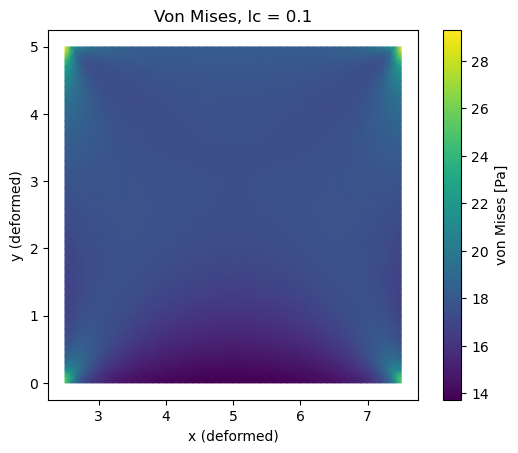

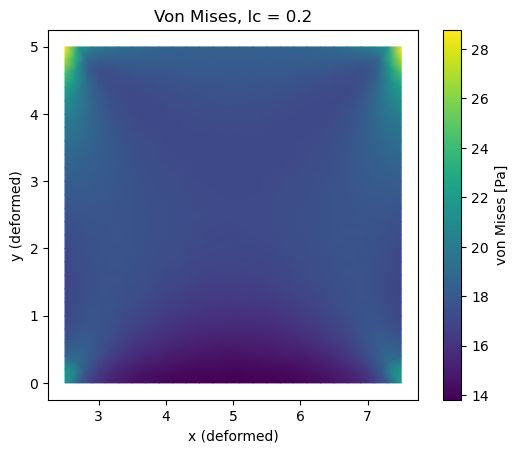

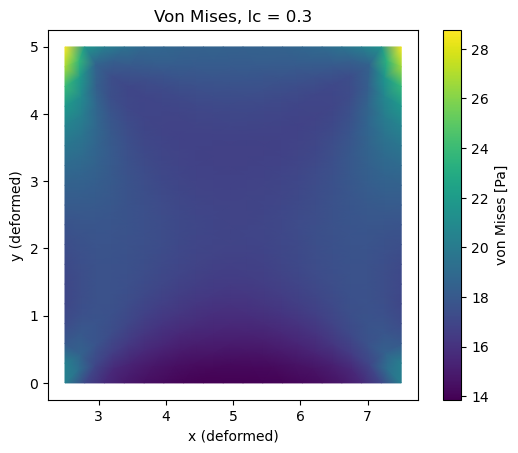

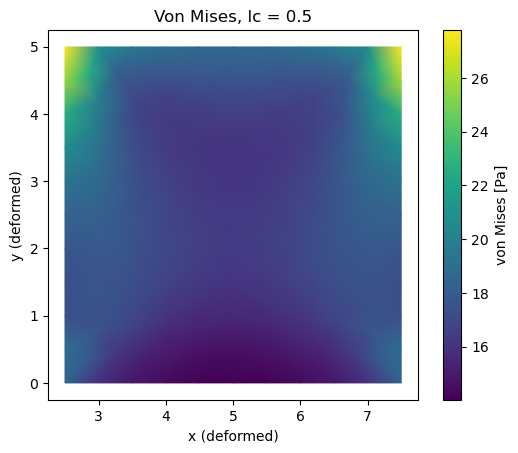

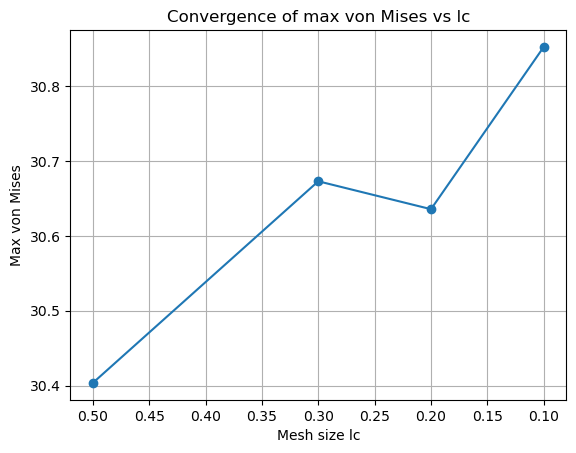

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
#TRY FOR HARDENING CASE POST-PROCESSING
# ---------- LOADER ----------

def load_case(lc):
    """
    Read results for a given mesh size lc from the Excel file
    FEM_results_lc_{lc}.xlsx
    Change the formatting in filename if your actual filenames differ.
    """
    filename = f"FEM_results_hardening_lc_{lc}.xlsx"   # or f"FEM_results_lc_{lc:.1f}.xlsx"
    
    nodes = pd.read_excel(filename, sheet_name="Nodes")
    elems = pd.read_excel(filename, sheet_name="Elements")
    vm    = pd.read_excel(filename, sheet_name="Von_Mises")
    
    return nodes, elems, vm

# ---------- VON MISES PLOT (DEFORMED MESH) ----------

def plot_deformed_vm(nodes, elems, vm, scale=1.0, title=None):
    # Nodal coordinates and displacements
    x  = nodes["x"].values
    y  = nodes["y"].values
    ux = nodes["ux"].values
    uy = nodes["uy"].values
    
    # Deformed coordinates
    x_def = x + scale * ux
    y_def = y + scale * uy

    # Triangulation (elements are 1-based in Excel → convert to 0-based)
    triangles = elems[["n1", "n2", "n3"]].values.astype(int) - 1
    triang = mtri.Triangulation(x_def, y_def, triangles)
    
    # --- Map element von Mises to nodes (simple averaging) ---
    elem_vm = vm["von_mises"].values
    n_nodes = len(x_def)
    nodal_vm = np.zeros(n_nodes)
    counts   = np.zeros(n_nodes)
    
    for e, tri_nodes in enumerate(triangles):
        for n in tri_nodes:
            nodal_vm[n] += elem_vm[e]
            counts[n]   += 1
    counts[counts == 0] = 1  # avoid division by zero
    nodal_vm /= counts
    
    # --- Plot ---
    fig, ax = plt.subplots()
    tpc = ax.tripcolor(triang, nodal_vm, shading="gouraud")
    fig.colorbar(tpc, ax=ax, label="von Mises [Pa]")
    
    ax.set_aspect("equal")
    ax.set_xlabel("x (deformed)")
    ax.set_ylabel("y (deformed)")
    if title:
        ax.set_title(title)
    else:
        ax.set_title("Deformed mesh coloured by von Mises")
    
    plt.show()

# ---------- MAX VON MISES FOR CONVERGENCE ----------

def compute_max_vm(vm):
    """Return maximum von Mises value from the DataFrame."""
    return vm["von_mises"].to_numpy().max()

# ---------- LOOP OVER lc VALUES ----------

lc_list = [0.1,0.2,0.3, 0.5]   # make sure these match the filenames you saved
lc_vals = []
vm_max_vals = []

for lc in lc_list:
    nodes, elems, vm = load_case(lc)
    
    # Plot field for each lc
    plot_deformed_vm(nodes, elems, vm, scale=1.0, title=f"Von Mises, lc = {lc}")
    
    # Compute max von Mises for convergence
    vm_max = compute_max_vm(vm)
    lc_vals.append(lc)
    vm_max_vals.append(vm_max)

# ---------- CONVERGENCE PLOT ----------

plt.figure()
plt.plot(lc_vals, vm_max_vals, marker="o")
plt.gca().invert_xaxis()  # optional: finer mesh on the right
plt.xlabel("Mesh size lc")
plt.ylabel("Max von Mises")
plt.title("Convergence of max von Mises vs lc")
plt.grid(True)
plt.show()


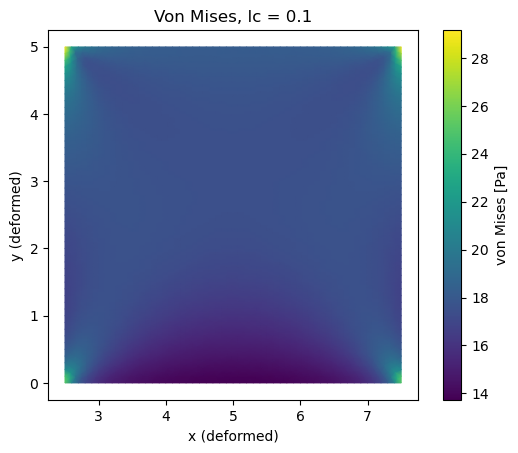

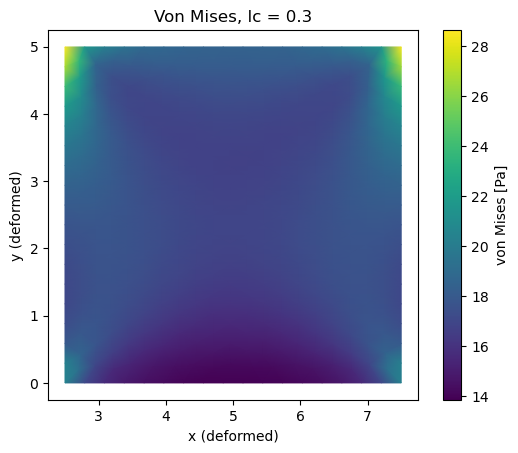

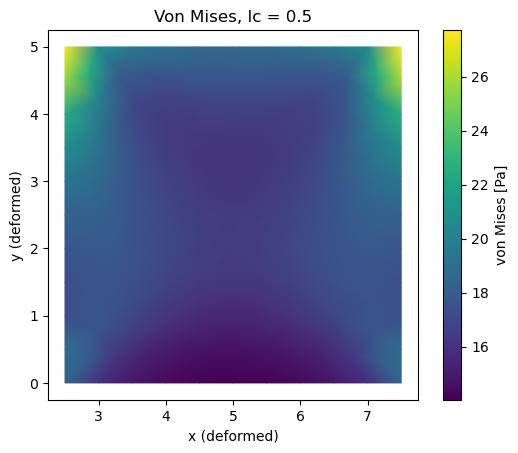

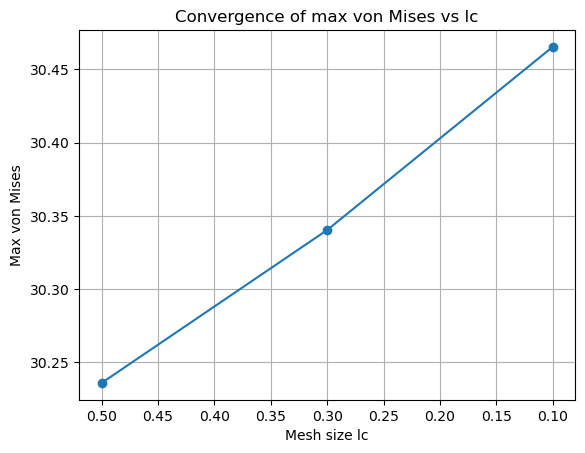

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

# ---------- LOADER ----------

def load_case(lc):
    """
    Read results for a given mesh size lc from the Excel file
    FEM_results_lc_{lc}.xlsx
    Change the formatting in filename if your actual filenames differ.
    """
    filename = f"FEM_results_lc_{lc}.xlsx"   # or f"FEM_results_lc_{lc:.1f}.xlsx"
    
    nodes = pd.read_excel(filename, sheet_name="Nodes")
    elems = pd.read_excel(filename, sheet_name="Elements")
    vm    = pd.read_excel(filename, sheet_name="Von_Mises")
    
    return nodes, elems, vm

# ---------- VON MISES PLOT (DEFORMED MESH) ----------

def plot_deformed_vm(nodes, elems, vm, scale=1.0, title=None):
    # Nodal coordinates and displacements
    x  = nodes["x"].values
    y  = nodes["y"].values
    ux = nodes["ux"].values
    uy = nodes["uy"].values
    
    # Deformed coordinates
    x_def = x + scale * ux
    y_def = y + scale * uy

    # Triangulation (elements are 1-based in Excel → convert to 0-based)
    triangles = elems[["n1", "n2", "n3"]].values.astype(int) - 1
    triang = mtri.Triangulation(x_def, y_def, triangles)
    
    # --- Map element von Mises to nodes (simple averaging) ---
    elem_vm = vm["von_mises"].values
    n_nodes = len(x_def)
    nodal_vm = np.zeros(n_nodes)
    counts   = np.zeros(n_nodes)
    
    for e, tri_nodes in enumerate(triangles):
        for n in tri_nodes:
            nodal_vm[n] += elem_vm[e]
            counts[n]   += 1
    counts[counts == 0] = 1  # avoid division by zero
    nodal_vm /= counts
    
    # --- Plot ---
    fig, ax = plt.subplots()
    tpc = ax.tripcolor(triang, nodal_vm, shading="gouraud")
    fig.colorbar(tpc, ax=ax, label="von Mises [Pa]")
    
    ax.set_aspect("equal")
    ax.set_xlabel("x (deformed)")
    ax.set_ylabel("y (deformed)")
    if title:
        ax.set_title(title)
    else:
        ax.set_title("Deformed mesh coloured by von Mises")
    
    plt.show()

# ---------- MAX VON MISES FOR CONVERGENCE ----------

def compute_max_vm(vm):
    """Return maximum von Mises value from the DataFrame."""
    return vm["von_mises"].to_numpy().max()

# ---------- LOOP OVER lc VALUES ----------

lc_list = [0.1, 0.3, 0.5]   # make sure these match the filenames you saved
lc_vals = []
vm_max_vals = []

for lc in lc_list:
    nodes, elems, vm = load_case(lc)
    
    # Plot field for each lc
    plot_deformed_vm(nodes, elems, vm, scale=1.0, title=f"Von Mises, lc = {lc}")
    
    # Compute max von Mises for convergence
    vm_max = compute_max_vm(vm)
    lc_vals.append(lc)
    vm_max_vals.append(vm_max)

# ---------- CONVERGENCE PLOT ----------

plt.figure()
plt.plot(lc_vals, vm_max_vals, marker="o")
plt.gca().invert_xaxis()  # optional: finer mesh on the right
plt.xlabel("Mesh size lc")
plt.ylabel("Max von Mises")
plt.title("Convergence of max von Mises vs lc")
plt.grid(True)
plt.show()
